In [12]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [13]:
import numpy as np

In [14]:
df = pd.read_csv("/content/diabetes.csv")

In [15]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [16]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [17]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [18]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [19]:
df.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [20]:
df.shape

(768, 9)

In [21]:
#ENCODE CATEGORICAL -> NUMERIC

In [22]:
le = {} #create empty dictionary
df_enc = df.copy() #here we just cop our original data
for col in df.columns: #it convert into the text using loop through of the column
    le[col] = LabelEncoder() #now create new label for current data
    df_enc[col] = le[col].fit_transform(df[col])

In [23]:
df_enc

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,86,22,28,0,123,350,29,1
1,1,23,19,22,0,62,196,10,0
2,8,121,17,0,0,30,368,11,1
3,1,27,19,16,62,77,53,0,0
4,0,75,4,28,102,209,514,12,1
...,...,...,...,...,...,...,...,...,...
763,10,39,25,41,108,118,55,42,0
764,2,60,21,20,0,155,187,6,0
765,5,59,22,16,71,58,115,9,0
766,1,64,14,0,0,95,195,26,1


In [24]:
#FEATURES & TARGET

In [26]:
x = df_enc[['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']]
y = df_enc['Outcome']

In [27]:
x

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,86,22,28,0,123,350,29
1,1,23,19,22,0,62,196,10
2,8,121,17,0,0,30,368,11
3,1,27,19,16,62,77,53,0
4,0,75,4,28,102,209,514,12
...,...,...,...,...,...,...,...,...
763,10,39,25,41,108,118,55,42
764,2,60,21,20,0,155,187,6
765,5,59,22,16,71,58,115,9
766,1,64,14,0,0,95,195,26


In [28]:
y

,Outcome
0,1
1,0
2,1
3,0
4,1
...,...
763,0
764,0
765,0
766,1


In [29]:
model = CategoricalNB() #apply model
model.fit(x,y) #fit the data

CategoricalNB()

In [34]:
test = [
    [6, 148, 72, 35, 0, 33.6, 0.627, 50], ]

In [35]:
test

[[6, 148, 72, 35, 0, 33.6, 0.627, 50]]

In [36]:
print('\n--- Prediction ------------------------------------->')
for t in test:
    encoded_row = [[
        le['Pregnancies'].transform([t[0]])[0],
        le['Glucose'].transform([t[1]])[0],
        le['BloodPressure'].transform([t[2]])[0],
        le['SkinThickness'].transform([t[3]])[0],
        le['Insulin'].transform([t[4]])[0],
        le['BMI'].transform([t[5]])[0],
        le['DiabetesPedigreeFunction'].transform([t[6]])[0],
        le['Age'].transform([t[7]])[0]
    ]]

    pred_enc = model.predict(encoded_row)[0]

    prediction = le['Outcome'].inverse_transform([pred_enc])[0]

    print(f"Input features: {t} => Predicted Outcome: {prediction}")


--- Prediction ------------------------------------->
Input features: [6, 148, 72, 35, 0, 33.6, 0.627, 50] => Predicted Outcome: 1


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [37]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x)
print(f"\nTraining Accuracy: {accuracy_score(y, y_pred)*100:.2f}%")


Training Accuracy: 92.84%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


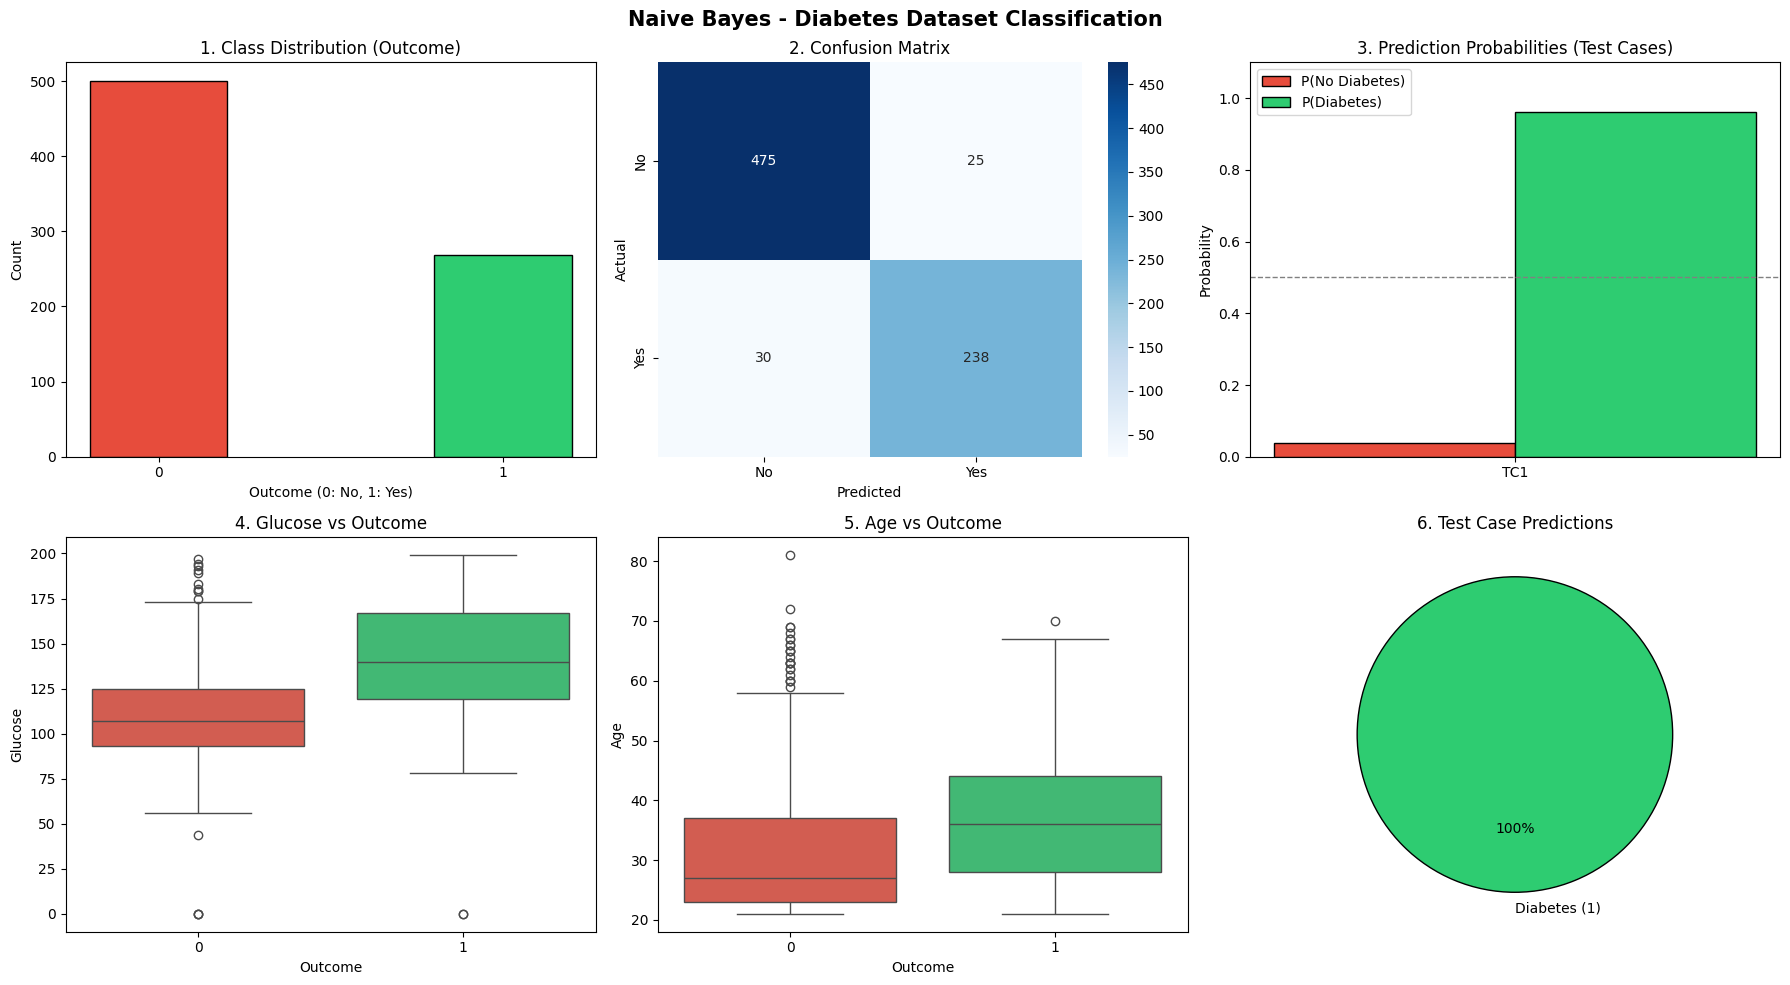

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Prepare prediction probabilities and predictions list for the test cases
probs_no = []
probs_yes = []
predictions = []
for t in test:
    row = [[
        le['Pregnancies'].transform([t[0]])[0],
        le['Glucose'].transform([t[1]])[0],
        le['BloodPressure'].transform([t[2]])[0],
        le['SkinThickness'].transform([t[3]])[0],
        le['Insulin'].transform([t[4]])[0],
        le['BMI'].transform([t[5]])[0],
        le['DiabetesPedigreeFunction'].transform([t[6]])[0],
        le['Age'].transform([t[7]])[0]
    ]]
    prob = model.predict_proba(row)[0]
    probs_no.append(prob[0])
    probs_yes.append(prob[1])

    # Generate predicted class name
    pred_class = le['Outcome'].inverse_transform(model.predict(row))[0]
    predictions.append(pred_class)

# Correct grid to 2 rows and 3 columns to host all plots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle(
    "Naive Bayes - Diabetes Dataset Classification", fontsize=15, fontweight="bold"
)

# 1. Class Distribution
counts = df["Outcome"].value_counts()
axes[0, 0].bar(
    counts.index.astype(str),
    counts.values,
    color=["#e74c3c", "#2ecc71"],
    edgecolor="black",
    width=0.4,
)
axes[0, 0].set_title("1. Class Distribution (Outcome)")
axes[0, 0].set_xlabel("Outcome (0: No, 1: Yes)")
axes[0, 0].set_ylabel("Count")

# 2. Confusion Matrix
cm = confusion_matrix(y, model.predict(x))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'], ax=axes[0, 1])
axes[0, 1].set_title("2. Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# 3. Prediction Probabilities
tc_labels = [f"TC{i+1}" for i in range(len(test))]
x_coords = np.arange(len(tc_labels))
w = 0.35
axes[0, 2].bar(x_coords - w/2, probs_no, w, label='P(No Diabetes)', color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_coords + w/2, probs_yes, w, label='P(Diabetes)', color='#2ecc71', edgecolor='black')
axes[0, 2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0, 2].set_title("3. Prediction Probabilities (Test Cases)")
axes[0, 2].set_xticks(x_coords)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].legend()

# 4. Glucose Distribution vs Outcome
sns.boxplot(data=df, x='Outcome', y='Glucose', ax=axes[1, 0], palette=['#e74c3c', '#2ecc71'], hue='Outcome', legend=False)
axes[1, 0].set_title("4. Glucose vs Outcome")
axes[1, 0].set_xlabel("Outcome")
axes[1, 0].set_ylabel("Glucose")

# 5. Age Distribution vs Outcome
sns.boxplot(data=df, x='Outcome', y='Age', ax=axes[1, 1], palette=['#e74c3c', '#2ecc71'], hue='Outcome', legend=False)
axes[1, 1].set_title("5. Age vs Outcome")
axes[1, 1].set_xlabel("Outcome")
axes[1, 1].set_ylabel("Age")

# 6. Test Case Predictions (Pie Chart)
pred_counts = pd.Series(predictions).value_counts()
colors_pie = ['#2ecc71' if label == 1 else '#e74c3c' for label in pred_counts.index]

axes[1, 2].pie(
    pred_counts.values,
    labels=[f"Diabetes ({l})" if l == 1 else f"No Diabetes ({l})" for l in pred_counts.index],
    autopct="%1.0f%%",
    colors=colors_pie,
    startangle=90,
    wedgeprops={'edgecolor': 'black'}
)
axes[1, 2].set_title("6. Test Case Predictions")

plt.tight_layout()
plt.show()